# 01. 탐색적 데이터 분석 (EDA)

> ⚠️ 본 시스템은 교육 목적으로 개발되었으며, 실제 금융 의사결정에 사용할 수 없습니다.

과제 노션의 리포트 내용 「문제 정의, EDA, 모델 비교, XAI 분석, 공정성 검증, ANOVA 통계 검증, 결론」 중 **EDA** 장의 재료입니다 (이슈 #83).

- **원본 데이터**: Kaggle Give Me Some Credit `data/raw/cs-training.csv`
- **대안 데이터·분할 데이터**: `python main_step1.py` 를 먼저 실행해야 생깁니다 (`data/intermediate/02_simulated.csv`, `data/splits/`)
- 그림은 `notebooks/figures/` 에 PNG로도 저장해 리포트에 그대로 씁니다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 프로젝트 폴더 찾기 (notebooks/ 안에서 실행해도, 프로젝트 폴더에서 실행해도 동작)
ROOT = Path.cwd()
while not (ROOT / 'main_step1.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG = ROOT / 'notebooks' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

# 한글 글꼴 (Noto CJK / 나눔 / 맑은 고딕 중 있는 것)
for name in ('Noto Sans CJK KR', 'Noto Sans CJK JP', 'Noto Serif CJK KR', 'Noto Serif CJK SC', 'NanumGothic', 'Malgun Gothic'):
    if any(name in f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

TARGET = 'SeriousDlqin2yrs'
ALT = ['telecom_payment_rate', 'utility_payment_rate', 'spending_consistency', 'regular_payment_count', 'app_login_frequency']
ALT_KO = {'telecom_payment_rate': '통신비 정상납부율', 'utility_payment_rate': '공과금 납부율',
          'spending_consistency': '소비 일관성', 'regular_payment_count': '정기결제 건수', 'app_login_frequency': '앱 로그인 빈도'}
DELINQ = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches='tight')
    print('저장:', (FIG / name).relative_to(ROOT))

raw = pd.read_csv(ROOT / 'data' / 'raw' / 'cs-training.csv', index_col=0)
sim = pd.read_csv(ROOT / 'data' / 'intermediate' / '02_simulated.csv')
print('원본', raw.shape, '| 대안 데이터 포함', sim.shape)

원본 (150000, 11) | 대안 데이터 포함 (150000, 20)


## 1. 데이터 개요

과제 노션: 「Give Me Some Credit · Kaggle 부도 예측 데이터 (150,000건)」, 「데이터 로드 시 컬럼명, 데이터 타입, 결측치 비율이 콘솔 또는 로그에 출력된다」

정답 칸 `SeriousDlqin2yrs` = 2년 안에 90일 이상 연체했으면 1.

In [2]:
# 칸 이름의 한글 뜻 (한글 이름은 거절 사유·SHAP 그림과 같은 src/explainer/feature_names.py 를 씀)
import sys
sys.path.insert(0, str(ROOT))
from src.explainer.feature_names import korean_name
COL_MEANING = {
    'SeriousDlqin2yrs': '정답. 2년 안에 90일 이상 연체했으면 1',
    'RevolvingUtilizationOfUnsecuredLines': '신용카드·신용한도 중 쓰고 있는 비율 (1 = 100%)',
    'age': '나이 (세)',
    'NumberOfTime30-59DaysPastDueNotWorse': '최근 2년 동안 30~59일 연체한 횟수',
    'DebtRatio': '월 부채 상환액 ÷ 월소득',
    'MonthlyIncome': '월소득',
    'NumberOfOpenCreditLinesAndLoans': '지금 가진 대출·신용카드 한도 개수',
    'NumberOfTimes90DaysLate': '90일 이상 연체한 횟수',
    'NumberRealEstateLoansOrLines': '부동산 담보대출 개수',
    'NumberOfTime60-89DaysPastDueNotWorse': '최근 2년 동안 60~89일 연체한 횟수',
    'NumberOfDependents': '부양가족 수 (본인 제외)',
    'telecom_payment_rate': '통신비를 제때 낸 비율 (0~1)',
    'utility_payment_rate': '공과금을 제때 낸 비율 (0~1)',
    'spending_consistency': '매달 소비가 얼마나 일정한지 (0~100점)',
    'regular_payment_count': '매달 정기결제·자동이체 건수 (0~20건)',
    'app_login_frequency': '한 달 금융앱 로그인 횟수 (0~30회)',
    'gender': '성별 (0 = 여성, 1 = 남성). 시뮬레이터가 만든 값, 공정성 검사에만 쓰고 모델 입력에서 뺌',
    'age_group': '연령대 (0 = 20-34세, 1 = 35-54세, 2 = 55세 이상). 공정성 검사에만 쓰고 모델 입력에서 뺌',
    'is_thin_filer': '씬파일러 표시 (1 = 씬파일러). 모델 입력에서 뺌',
    'customer_id': '고객 번호. 모델 입력에서 뺌',
}
KO_NAME = {'SeriousDlqin2yrs': '연체 여부 (정답)', 'gender': '성별', 'age_group': '연령대',
           'is_thin_filer': '씬파일러 표시', 'customer_id': '고객 번호'}
ko = lambda c: KO_NAME.get(c, korean_name(c))

In [3]:
info = pd.DataFrame({'한글 이름': [ko(c) for c in raw.columns],
                     '뜻': [COL_MEANING.get(c, '-') for c in raw.columns],
                     '자료형': raw.dtypes.astype(str), '결측 수': raw.isna().sum(),
                     '결측 비율(%)': (raw.isna().mean() * 100).round(2)})
print(f"인원 {len(raw):,}명, 연체율 {raw[TARGET].mean():.2%} (연체 {int(raw[TARGET].sum()):,}명)")
info

인원 150,000명, 연체율 6.68% (연체 10,026명)


,한글 이름,뜻,자료형,결측 수,결측 비율(%)
SeriousDlqin2yrs,연체 여부 (정답),정답. 2년 안에 90일 이상 연체했으면 1,int64,0,0.00
RevolvingUtilizationOfUnsecuredLines,한도 사용 비율,신용카드·신용한도 중 쓰고 있는 비율 (1 = 100%),float64,0,0.00
age,나이,나이 (세),int64,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,최근 2년 30~59일 연체 횟수,최근 2년 동안 30~59일 연체한 횟수,int64,0,0.00
DebtRatio,부채 비율,월 부채 상환액 ÷ 월소득,float64,0,0.00
MonthlyIncome,월소득,월소득,float64,29731,19.82
NumberOfOpenCreditLinesAndLoans,보유 대출·신용 한도 개수,지금 가진 대출·신용카드 한도 개수,int64,0,0.00
NumberOfTimes90DaysLate,90일 이상 연체 횟수,90일 이상 연체한 횟수,int64,0,0.00
NumberRealEstateLoansOrLines,부동산 담보대출 개수,부동산 담보대출 개수,int64,0,0.00
NumberOfTime60-89DaysPastDueNotWorse,최근 2년 60~89일 연체 횟수,최근 2년 동안 60~89일 연체한 횟수,int64,0,0.00


`main_step1.py` 가 원본에 더한 칸 (대안 데이터 5개는 과제 노션 「시뮬레이터가 다음 5개 대안 변수를 생성한다」):

In [4]:
added = [c for c in sim.columns if c not in raw.columns and c != 'Unnamed: 0']
pd.DataFrame({'한글 이름': [ko(c) for c in added], '뜻': [COL_MEANING.get(c, '-') for c in added],
              '자료형': sim[added].dtypes.astype(str)}, index=added)

,한글 이름,뜻,자료형
telecom_payment_rate,통신비 정상납부율,통신비를 제때 낸 비율 (0~1),float64
utility_payment_rate,공과금 납부율,공과금을 제때 낸 비율 (0~1),float64
spending_consistency,소비 일관성 점수,매달 소비가 얼마나 일정한지 (0~100점),float64
regular_payment_count,정기결제 건수,매달 정기결제·자동이체 건수 (0~20건),int64
app_login_frequency,앱 로그인 빈도,한 달 금융앱 로그인 횟수 (0~30회),int64
gender,성별,"성별 (0 = 여성, 1 = 남성). 시뮬레이터가 만든 값, 공정성 검사에만 쓰고 ...",int64
age_group,연령대,"연령대 (0 = 20-34세, 1 = 35-54세, 2 = 55세 이상). 공정성 ...",int64
is_thin_filer,씬파일러 표시,씬파일러 표시 (1 = 씬파일러). 모델 입력에서 뺌,int64


저장: notebooks/figures/01_target_balance.png


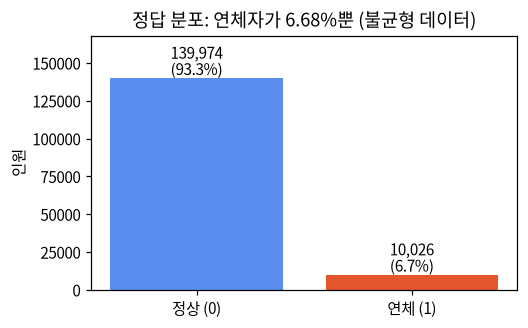

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
counts = raw[TARGET].value_counts().sort_index()
ax.bar(['정상 (0)', '연체 (1)'], counts.values, color=['#5b8def', '#e4572e'])
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / len(raw):.1%})', ha='center', va='bottom')
ax.set_ylabel('인원'); ax.set_title('정답 분포: 연체자가 6.68%뿐 (불균형 데이터)')
ax.set_ylim(0, counts.max() * 1.2)
save(fig, '01_target_balance.png'); plt.show()

## 2. 월소득 빈칸과 부채비율

과제 노션: 「결측치 처리 로직이 구현되어 있다 (중앙값/평균값 대체 또는 삭제)」

- 월소득 빈칸은 **"소득 없음"이 아니라 "소득을 모름"** 입니다. 소득이 0인 사람은 따로 있습니다.
- 월소득이 빈 사람은 부채비율(`DebtRatio`) 칸에 비율이 아니라 **금액**이 들어 있습니다 (중앙값 약 1,159). 전처리에서 월소득 중앙값으로 나눠 비율로 바꿉니다 (#54).
- 월소득이 **0이거나 아주 작은 사람**도 부채비율이 금액으로 남아 있습니다 (나눌 소득이 없어서). 지금 전처리는 빈칸인 사람만 바꾸므로 이 사람들은 그대로이며, 이상값 정리 보류 항목으로 리포트 한계에 적습니다.

In [6]:
inc = raw['MonthlyIncome']
groups = {'월소득 빈칸': inc.isna(), '월소득 0': inc == 0, '월소득 1~100': inc.between(1, 100), '월소득 101 이상': inc > 100}
table = pd.DataFrame({
    '인원': {k: int(m.sum()) for k, m in groups.items()},
    '비율(%)': {k: round(m.mean() * 100, 1) for k, m in groups.items()},
    '연체율(%)': {k: round(raw.loc[m, TARGET].mean() * 100, 2) for k, m in groups.items()},
    'DebtRatio 중앙값': {k: round(raw.loc[m, 'DebtRatio'].median(), 2) for k, m in groups.items()},
})
print('월소득 중앙값(빈칸 제외):', inc.median(), '| 평균:', round(inc.mean(), 1))
table

월소득 중앙값(빈칸 제외): 5400.0 | 평균: 6670.2


,인원,비율(%),연체율(%),DebtRatio 중앙값
월소득 빈칸,29731,19.8,5.61,1159.00
월소득 0,1634,1.1,4.04,930.00
월소득 1~100,667,0.4,2.70,455.50
월소득 101 이상,117968,78.6,7.01,0.29


저장: notebooks/figures/02_debt_ratio_fix.png


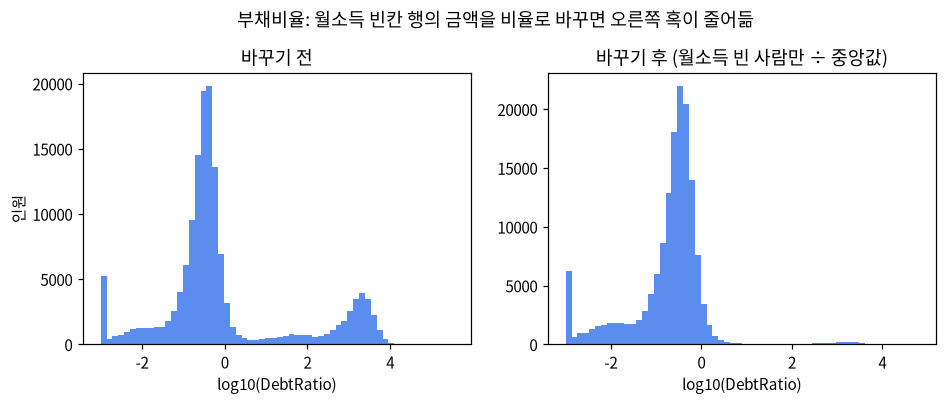

DebtRatio 중앙값  전: 0.367  후: 0.283  |  99% 지점  전: 4,979  후: 266.0
바꾼 뒤에도 금액으로 남은 사람(월소득 0~100, DebtRatio 10 초과): 2,020명 → 이상값 정리 보류(아래 3절)


In [7]:
med = inc.median()
before = raw['DebtRatio']
after = before.where(inc.notna(), before / med)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, s, title in ((axes[0], before, '바꾸기 전'), (axes[1], after, '바꾸기 후 (월소득 빈 사람만 ÷ 중앙값)')):
    ax.hist(np.log10(s.clip(lower=1e-3)), bins=60, color='#5b8def')
    ax.set_xlabel('log10(DebtRatio)'); ax.set_title(title)
axes[0].set_ylabel('인원')
fig.suptitle('부채비율: 월소득 빈칸 행의 금액을 비율로 바꾸면 오른쪽 혹이 줄어듦', y=1.06)
save(fig, '02_debt_ratio_fix.png'); plt.show()
print(f"DebtRatio 중앙값  전: {before.median():.3f}  후: {after.median():.3f}  |  99% 지점  전: {before.quantile(.99):,.0f}  후: {after.quantile(.99):,.1f}")
left = (inc.between(0, 100)) & (after > 10)
print(f"바꾼 뒤에도 금액으로 남은 사람(월소득 0~100, DebtRatio 10 초과): {int(left.sum()):,}명 → 이상값 정리 보류(아래 3절)")

## 3. 금융 변수 분포와 이상값

이상값은 **정리하지 않고 그대로 둡니다** (팀 결정, 과제 노션에 정리 요구 없음). 리포트 한계에 기록합니다.

In [8]:
outliers = {
    '연체 칸에 96·98 코드가 있는 사람': int(raw[DELINQ].isin([96, 98]).any(axis=1).sum()),
    '한도 사용 비율 10 초과': int((raw['RevolvingUtilizationOfUnsecuredLines'] > 10).sum()),
    '월소득 0 또는 1': int(inc.isin([0, 1]).sum()),
    '나이 0세': int((raw['age'] == 0).sum()),
    '나이 100세 초과': int((raw['age'] > 100).sum()),
}
pd.Series(outliers, name='인원').to_frame()

,인원
연체 칸에 96·98 코드가 있는 사람,269
한도 사용 비율 10 초과,241
월소득 0 또는 1,2239
나이 0세,1
나이 100세 초과,13


저장: notebooks/figures/03_financial_distributions.png


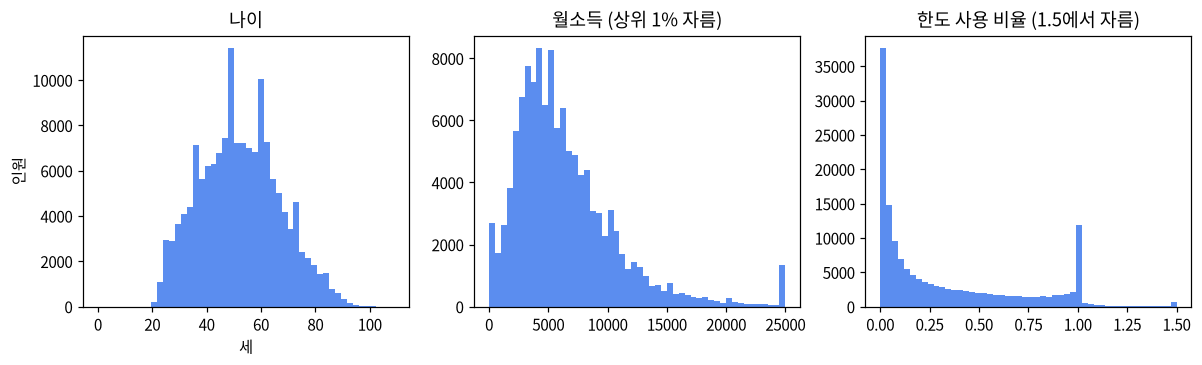

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(raw['age'], bins=50, color='#5b8def'); axes[0].set_title('나이'); axes[0].set_xlabel('세')
axes[1].hist(inc.dropna().clip(upper=inc.quantile(.99)), bins=50, color='#5b8def'); axes[1].set_title('월소득 (상위 1% 자름)')
axes[2].hist(raw['RevolvingUtilizationOfUnsecuredLines'].clip(upper=1.5), bins=50, color='#5b8def'); axes[2].set_title('한도 사용 비율 (1.5에서 자름)')
axes[0].set_ylabel('인원')
save(fig, '03_financial_distributions.png'); plt.show()

## 4. 대안 데이터 5개

과제 노션: 「시뮬레이터가 다음 5개 대안 변수를 생성한다」, 「생성된 대안 변수와 Target 변수 간 상관계수가 0.3 ~ 0.5 범위 내에 있음을 `df.corr()` 또는 리포트에서 확인할 수 있다」

- 팀 결정(#36): 상관계수 **크기**를 0.3~0.5로 맞추고, 과제 노션 예시 코드(`0.85 - 0.2 * target`)처럼 **연체자일수록 낮게** 만듭니다 (그래서 부호는 음수).
- 시뮬레이터 시드 42로 고정 (#76) → 누가 실행해도 같은 값.

In [10]:
corr = sim[ALT + [TARGET]].corr()[TARGET].drop(TARGET)
check = pd.DataFrame({'상관계수 (df.corr())': corr.round(3), '크기 0.3~0.5 안?': corr.abs().between(0.3, 0.5),
                      '정상 평균': sim.groupby(TARGET)[ALT].mean().loc[0].round(3),
                      '연체 평균': sim.groupby(TARGET)[ALT].mean().loc[1].round(3)})
check.index = [ALT_KO[c] for c in check.index]
check

,상관계수 (df.corr()),크기 0.3~0.5 안?,정상 평균,연체 평균
통신비 정상납부율,-0.436,True,0.906,0.804
공과금 납부율,-0.400,True,0.858,0.732
소비 일관성,-0.433,True,88.718,83.727
정기결제 건수,-0.383,True,11.365,10.265
앱 로그인 빈도,-0.345,True,20.766,19.220


저장: notebooks/figures/04_alt_by_target.png


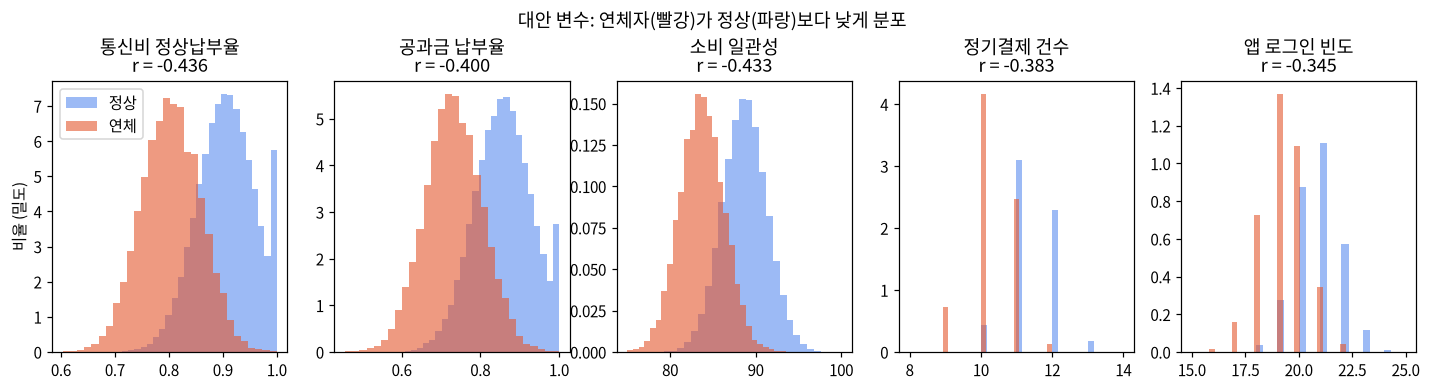

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, c in zip(axes, ALT):
    for y, color, label in ((0, '#5b8def', '정상'), (1, '#e4572e', '연체')):
        ax.hist(sim.loc[sim[TARGET] == y, c], bins=30, density=True, alpha=.6, color=color, label=label)
    ax.set_title(f"{ALT_KO[c]}\nr = {corr[c]:.3f}")
axes[0].legend(); axes[0].set_ylabel('비율 (밀도)')
fig.suptitle('대안 변수: 연체자(빨강)가 정상(파랑)보다 낮게 분포', y=1.08)
save(fig, '04_alt_by_target.png'); plt.show()

## 5. 씬파일러

과제 노션 정의: 「금융 연체 관련 컬럼 2개 이상 결측치이거나 신용카드 거래 이력이 12개월 미만인 고객」

- 이 데이터에는 연체 칸이 빈 사람이 없고(0명), 카드 사용 기간 칸도 없어서 과제 노션 정의로는 **0명** 입니다.
- 그래서 팀 기준(#15): **보유 대출·신용 한도 1개 이하 + 부동산 담보대출 0 + 연체 기록 0**. 근거는 아래처럼 기록이 적을수록 연체율이 높기 때문입니다.

In [12]:
print('과제 노션 기준 1 (연체 칸 2개 이상 빈칸):', int((raw[DELINQ].isna().sum(axis=1) >= 2).sum()), '명')
clean = (raw[DELINQ].fillna(0).sum(axis=1) == 0) & (raw['NumberRealEstateLoansOrLines'] == 0)
lines = raw.loc[clean, 'NumberOfOpenCreditLinesAndLoans'].clip(upper=3).map({0: '0개', 1: '1개', 2: '2개', 3: '3개 이상'})
basis = raw.loc[clean].groupby(lines)[TARGET].agg(['count', 'mean']).rename(columns={'count': '인원', 'mean': '연체율'})
basis['연체율'] = (basis['연체율'] * 100).round(1).astype(str) + '%'
print('연체 기록 0 · 부동산 담보대출 0 인 사람의 보유 계좌 수별 연체율')
basis

과제 노션 기준 1 (연체 칸 2개 이상 빈칸): 0 명
연체 기록 0 · 부동산 담보대출 0 인 사람의 보유 계좌 수별 연체율


,인원,연체율
NumberOfOpenCreditLinesAndLoans,,
0개,992,13.0%
1개,3118,5.3%
2개,4296,2.9%
3개 이상,35504,2.6%


In [13]:
thin = sim['is_thin_filer'] == 1
summary = pd.DataFrame({
    '인원': [int(thin.sum()), int((~thin).sum())],
    '비율(%)': [round(thin.mean() * 100, 2), round((~thin).mean() * 100, 2)],
    '연체율(%)': [round(sim.loc[thin, TARGET].mean() * 100, 2), round(sim.loc[~thin, TARGET].mean() * 100, 2)],
    '35세 미만 비율(%)': [round((sim.loc[thin, 'age'] < 35).mean() * 100, 1), round((sim.loc[~thin, 'age'] < 35).mean() * 100, 1)],
}, index=['씬파일러', '일반'])
summary

,인원,비율(%),연체율(%),35세 미만 비율(%)
씬파일러,4110,2.74,7.18,38.7
일반,145890,97.26,6.67,12.1


저장: notebooks/figures/05_thin_filer_age.png


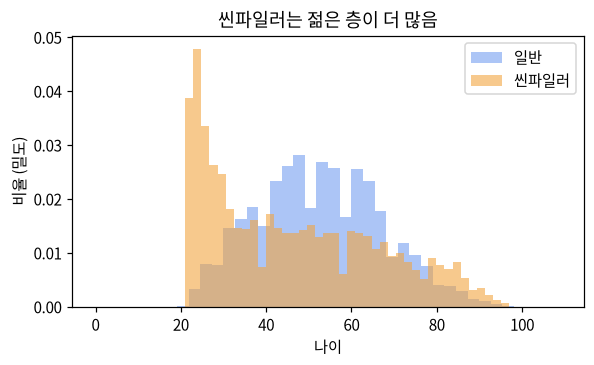

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(sim.loc[~thin, 'age'], bins=40, density=True, alpha=.5, color='#5b8def', label='일반')
ax.hist(sim.loc[thin, 'age'], bins=40, density=True, alpha=.6, color='#f2a541', label='씬파일러')
ax.set_xlabel('나이'); ax.set_ylabel('비율 (밀도)'); ax.legend(); ax.set_title('씬파일러는 젊은 층이 더 많음')
save(fig, '05_thin_filer_age.png'); plt.show()

## 6. 성별·연령대 (공정성 검증의 보호 속성)

과제 노션: 「보호 속성으로 성별(male/female)과 연령대(20-34/35-54/55+)를 사용한다」

성별은 시뮬레이터가 50:50으로 만들고(편향 `bias_ratio=0`), 연령대는 나이로 나눕니다. 두 칸 모두 **모델 입력에서는 빼고** 공정성 검사에만 씁니다 (과제 노션 「민감 정보 … 를 피처로 사용하는 것을 금지한다」).

In [15]:
age_group = pd.cut(sim['age'], bins=[0, 34, 54, 200], labels=['20-34', '35-54', '55+'])
demo = pd.concat({
    '성별': sim.groupby(sim['gender'].map({0: 'female', 1: 'male'}))[TARGET].agg(인원='count', 연체율='mean'),
    '연령대': sim.groupby(age_group, observed=True)[TARGET].agg(인원='count', 연체율='mean'),
})
demo['연체율'] = (demo['연체율'] * 100).round(2).astype(str) + '%'
demo

인원     연체율
성별  female  74934    6.7%
    male    75066   6.67%
연령대 20-34   19239  11.18%
    35-54   65339   8.32%
    55+     65421   3.73%

## 7. Train / Validation / Test 분할

과제 노션: 「Train/Validation/Test 분할 비율이 **70:15:15** 또는 80:10:10이다.」, 「분할 시 `stratify=y` 옵션이 적용되어 클래스 비율이 유지된다.」

In [16]:
rows = {}
for name in ('train', 'val', 'test'):
    df = pd.read_csv(ROOT / 'data' / 'splits' / f'{name}_processed.csv')
    rows[name] = {'인원': len(df), '비율(%)': 0, '연체율(%)': round(df[TARGET].mean() * 100, 2),
                  '씬파일러': int(df['is_thin_filer'].sum()), '칸 수': df.shape[1]}
split = pd.DataFrame(rows).T
split[['인원', '씬파일러', '칸 수']] = split[['인원', '씬파일러', '칸 수']].astype(int)
split['비율(%)'] = (split['인원'] / split['인원'].sum() * 100).round(1)
split.index = ['Train', 'Validation', 'Test']
split

,인원,비율(%),연체율(%),씬파일러,칸 수
Train,105000,70.0,6.68,2892,20
Validation,22500,15.0,6.68,593,20
Test,22500,15.0,6.68,625,20


## 정리

| 확인한 것 | 결과 |
|---|---|
| 데이터 | 150,000명, 연체율 6.68% (불균형) |
| 결측 | 월소득 19.8%("소득 모름", 소득 0과 다름), 부양가족 2.6% → 중앙값으로 채움 |
| 부채비율 | 월소득 빈칸 행은 금액 → 월소득 중앙값으로 나눠 비율로 |
| 이상값 | 정리하지 않음, 리포트 한계에 기록 |
| 대안 변수 | 5개 모두 상관계수 크기 0.3~0.5, 연체자일수록 낮음 |
| 씬파일러 | 과제 노션 정의로는 0명 → 팀 기준 4,110명 (2.74%), 연체율이 더 높고 젊은 층이 많음 |
| 분할 | Train 105,000 / Validation 22,500 / Test 22,500, 세 묶음 연체율 같음 |

> ⚠️ 본 시스템은 교육 목적으로 개발되었으며, 실제 금융 의사결정에 사용할 수 없습니다.